# Exploratory Data Analysis for Finance
## German Credit Risk Dataset —  demo


## About the dataset

German Credit Risk data: applicant information such as age, housing, account details, credit amount, duration, and **Risk** (good/bad).

 The main question I keep in mind: *What can these variables tell me about credit risk?*

 | Column | Type | Description |
|---|---|---|
| `Age` | numeric | Applicant's age, in years |
| `Sex` | categorical | `male` / `female` |
| `Job` | numeric (ordinal) | Skill level, coded 0–3 (0 = unskilled non-resident, 3 = highly skilled) |
| `Housing` | categorical | `own`, `rent`, or `free` |
| `SavingAccounts` | categorical | `little`, `moderate`, `quite rich`, `rich` (missing = no savings account on record) |
| `CheckingAccount` | categorical | `little`, `moderate`, `rich` (missing = no checking account on record) |
| `CreditAmount` | numeric | Requested credit amount (in Deutsche Mark) |
| `Duration` | numeric | Loan duration, in months |
| `Purpose` | categorical | What the loan is for, e.g. `car`, `radio/TV`, `education`, `business` |
| `Risk` | categorical (target-like) | `good` or `bad` credit risk — the outcome a bank would ultimately want to predict |

## Step 2.1 — Load packages

In [27]:
#  note: I import the libraries I need for handling data, plotting, and preprocessing.
%matplotlib inline

import pandas as pd            # DataFrames: loading, cleaning and exploring tabular data
import numpy as np             # Fast numeric arrays and math operations

import matplotlib.pyplot as plt    # Base plotting library (histograms, boxplots, etc.)
import seaborn as sns              # Higher-level statistical plots, built on top of matplotlib

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.feature_selection import SelectKBest, f_classif

sns.set_style("whitegrid")                 # Clean grid background for all plots
plt.rcParams["figure.figsize"] = (10, 5)   # Default figure size
pd.set_option("display.width", 100)        # Wider console output for DataFrames
pd.set_option("display.max_columns", 20)   # Show all columns when printing

print("All packages loaded successfully.")


All packages loaded successfully.


## Step 2.2 — Load the dataset

In [28]:
#  note: I load the CSV into a DataFrame called `dataset`. Everything starts from this table.
# Load the German Credit dataset

DATA_PATH = "german_credit_data.csv"
dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")


Dataset loaded: 1000 rows, 10 columns


## Step 3 — Exploratory Data Analysis (EDA)

### 3.1 Descriptive statistics

I start with basic checks, then move to charts. This helps me see what needs attention.

In [29]:
# note: To take a quick first look at the actual rows I use.
dataset.head()
# the output : first 5 rows in the dataset 
# If we enter a number with the code the lines return to the number entered in the code

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [30]:
# note: This tells me the dataset size: rows first, then columns.
print("Shape (rows, columns):", dataset.shape)


Shape (rows, columns): (1000, 10)


In [31]:
# note: I check whether each column is numeric or categorical (Check the Data_Type).
dataset.dtypes


Age                 int64
Sex                object
Job                 int64
Housing            object
SavingAccounts     object
CheckingAccount    object
CreditAmount        int64
Duration            int64
Purpose            object
Risk               object
dtype: object

In [32]:
#note: I focus on the ranges and averages here; unusual values might need attention.
# Quick thought: Do the minimum and maximum values make sense?

dataset.describe()


,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [33]:
# note: For text columns, I check the most frequent category and how many values are available.

dataset.describe(exclude="number")


,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [34]:
# note: I count missing entries before deciding how to handle them.

missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)


Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


In [35]:
# note: I check the balance between good and bad credit risk cases.
# Class balance matters if I build a classifier later.

print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")


Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


### Figure — missing values by column

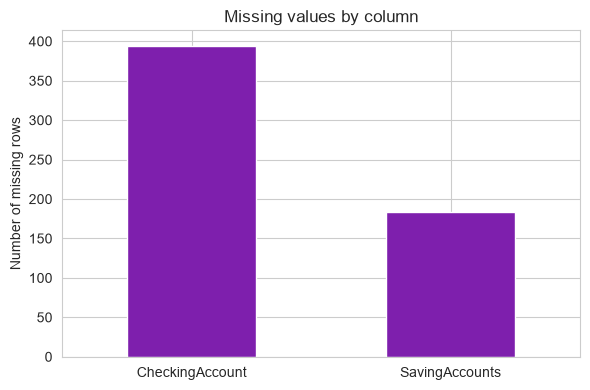

In [36]:
# note: The bars make it easier to see which columns have missing values.
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(6, 4))
missing_counts.plot(kind="bar", color="#7E1FAD")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### 3.2 Data visualization

#### Univariate plots



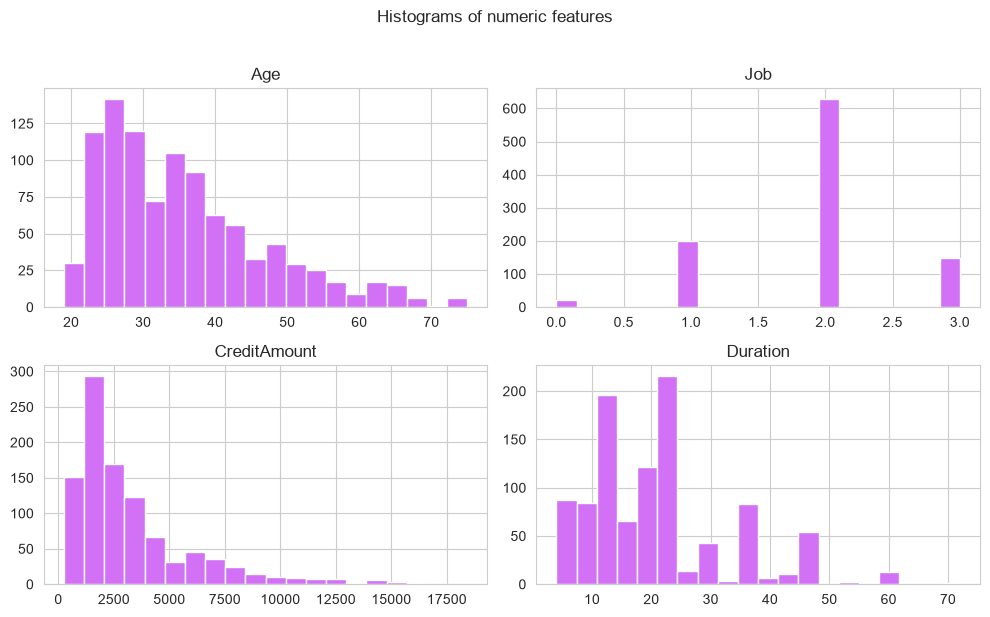

In [37]:
# note: Histograms help me notice the spread, skewness, and possible extreme values.

numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#D271F6", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()


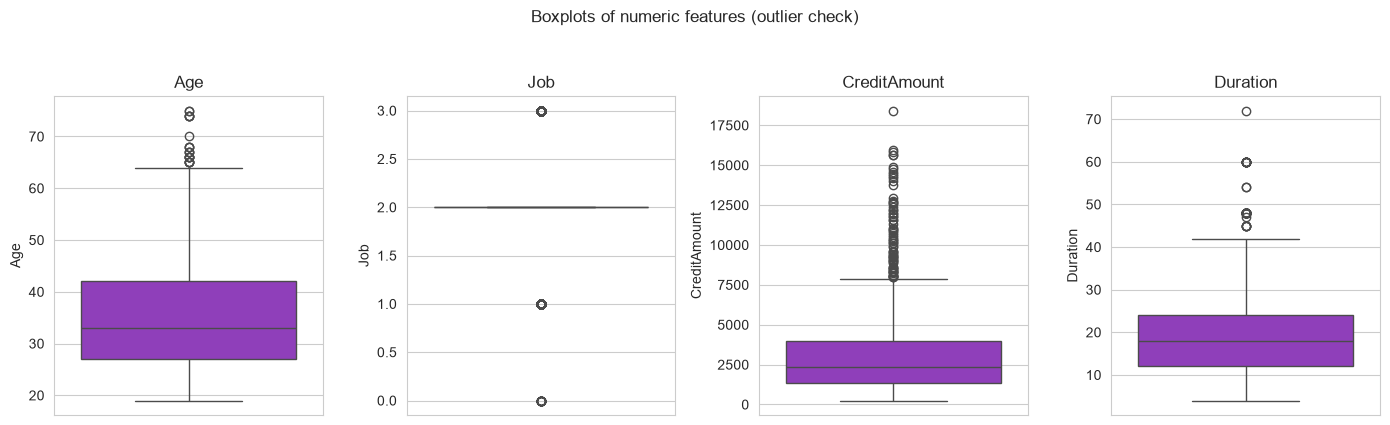

In [38]:
# note: I use boxplots to spot observations that sit far from most of the data.
# An outlier is a signal to investigate, not a reason to delete a row automatically.

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#952ACFCC")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()



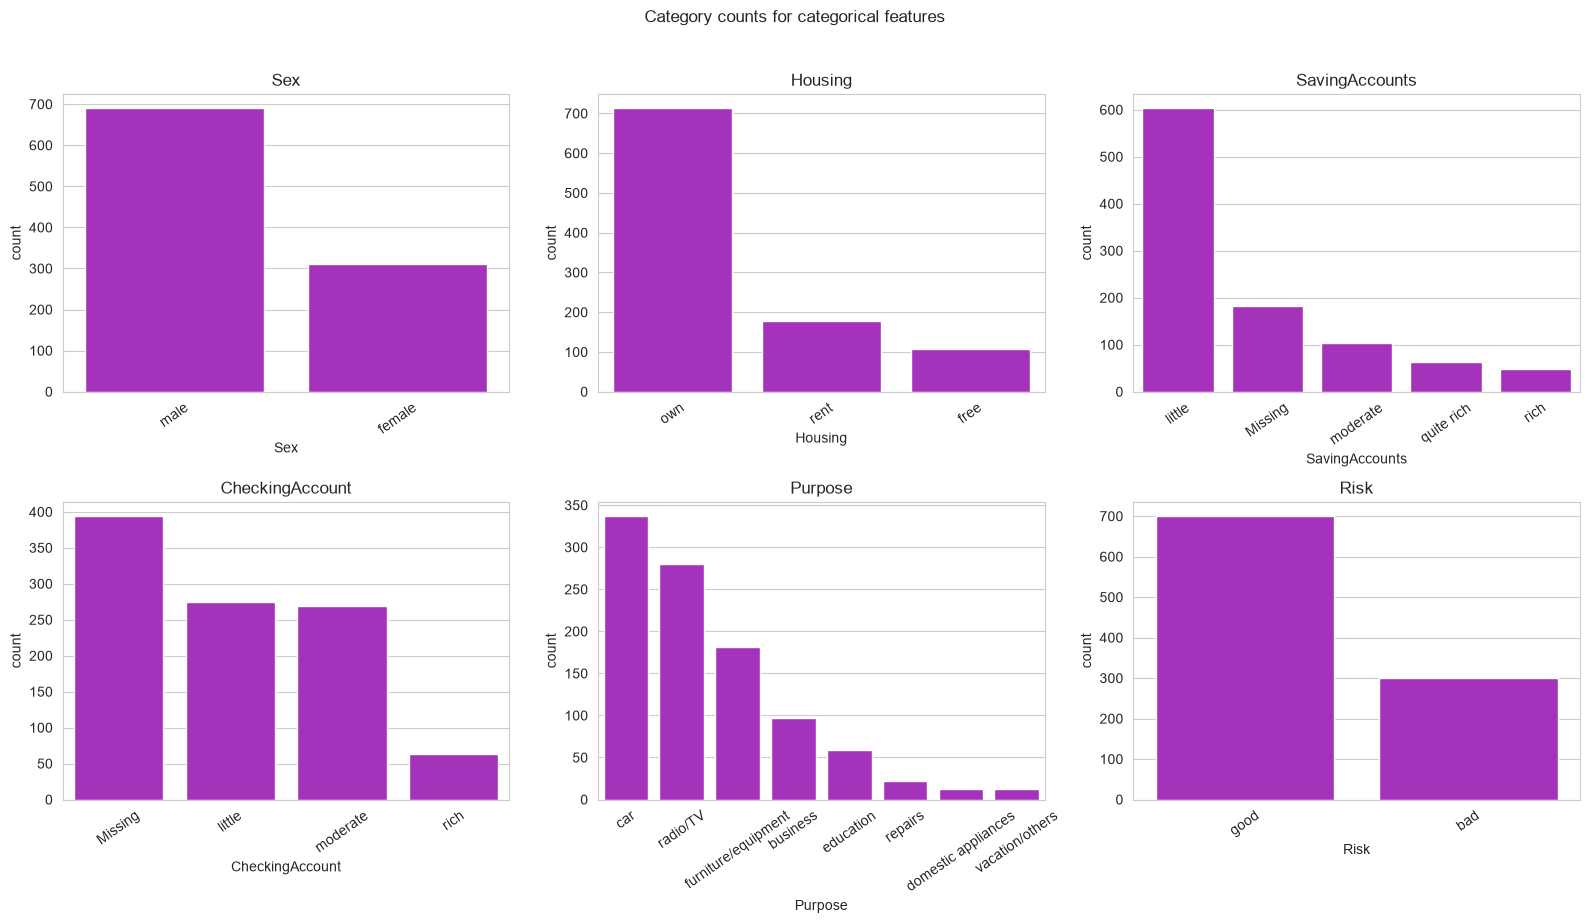

In [39]:
# note: These plots help me compare category frequencies, including missing entries.

categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    col_data = dataset[col].fillna("Missing")
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#B51CD0")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()


#### Multivariate plots

Now I look for relationships between features and between each feature and credit risk.

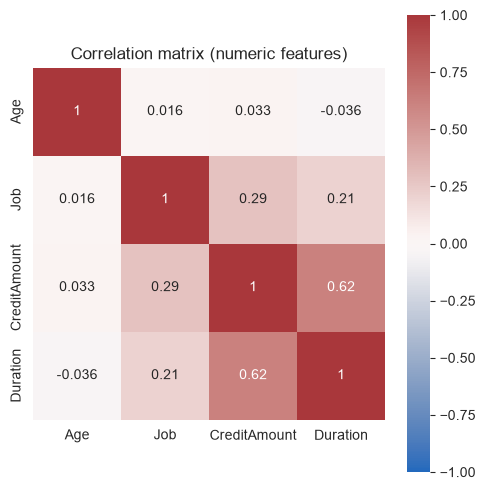

In [40]:
# note: I use the heatmap to check linear relationships between numeric variables.
# Correlation does not tell me that one variable causes another.

plt.figure(figsize=(5, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()


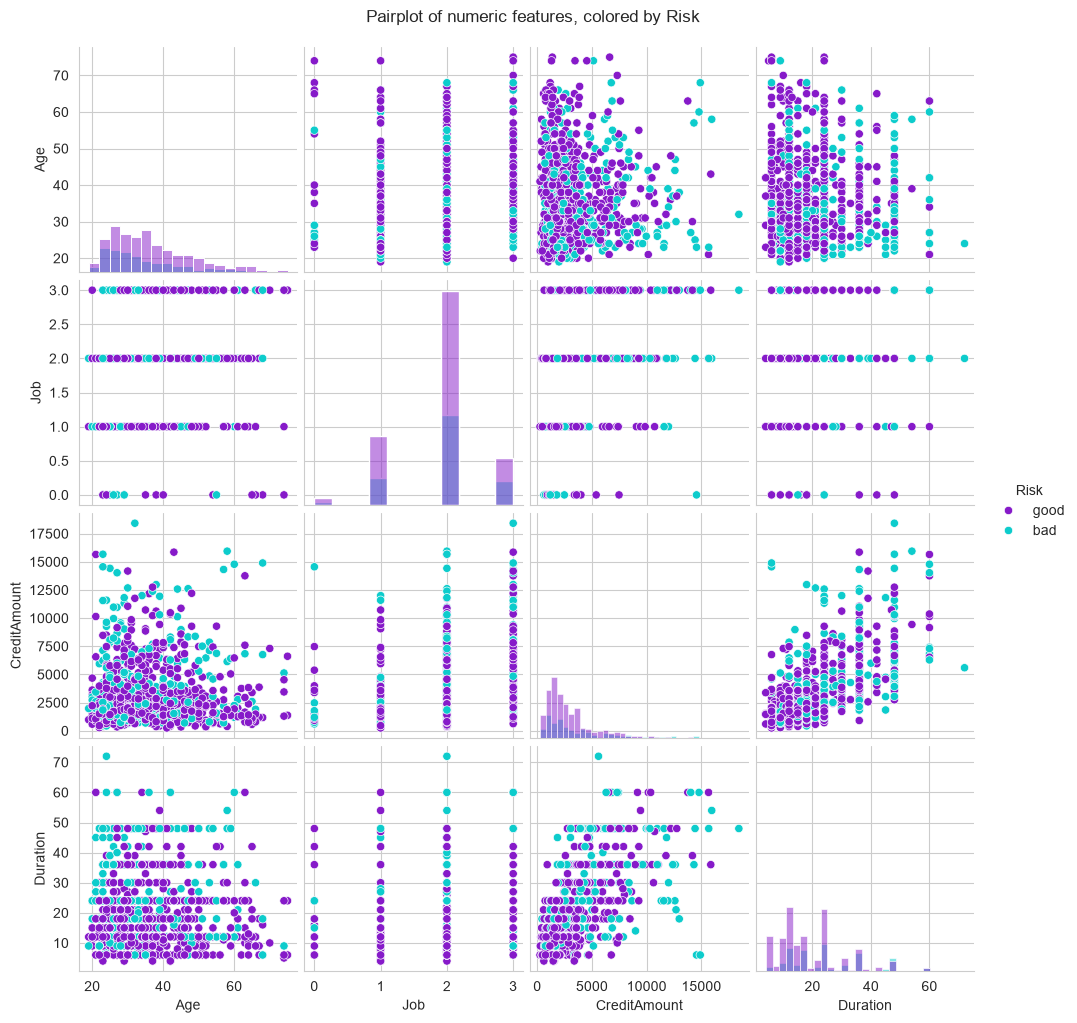

In [41]:
# note: The pairplot helps me look for visible differences between risk groups.

sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#861AC9", "bad": "#0DCCCC"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()


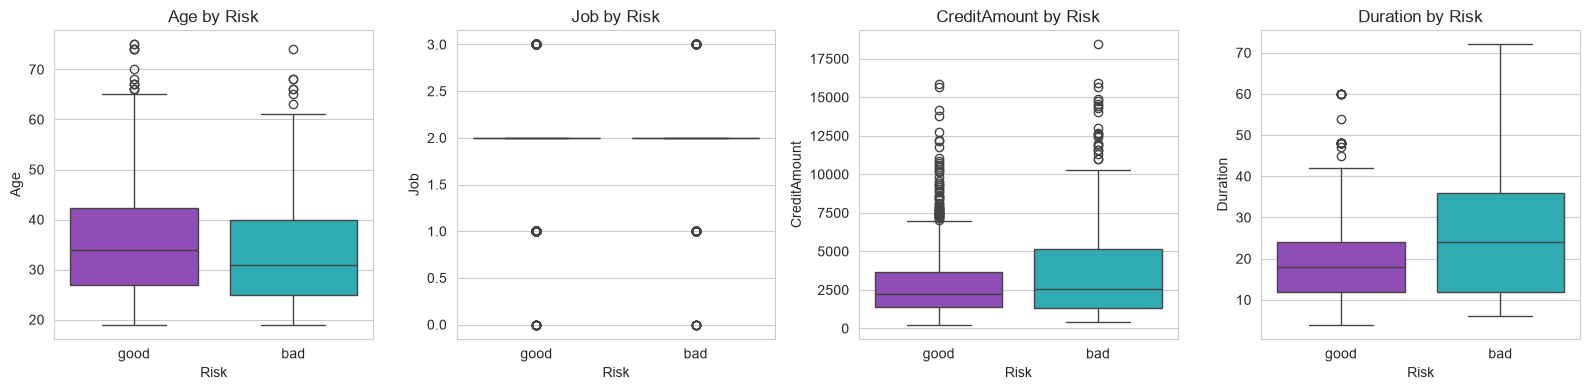

In [42]:
# note: Here I compare each numeric feature across the two risk categories.

fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#943BC8", "bad": "#1CC0C8"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()



## Step 4 — Data Preparation

### 4.1 Data cleaning — handling missing values



In [43]:
#  note: I keep the original data unchanged and fill the missing account entries with `none` for this demo.
# Important: missing does not always mean “no account”; this is a classroom assumption.

df_clean = dataset.copy()

df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

print("Remaining missing values:\n")
print(df_clean.isna().sum())


Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


### 4.2 Data transformation — encoding & scaling

I convert categories to numbers and bring numeric features onto a comparable scale.

In [44]:
# note: I convert categories into numeric labels. For real modeling, unordered categories may need one-hot encoding.

df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}  # keep the fitted encoders in case we need to decode values later
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")


Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [45]:
# note: I standardize numeric values so their different units do not dominate comparisons.
# In a real ML pipeline, I would fit the scaler on the training data only.

scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))


Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


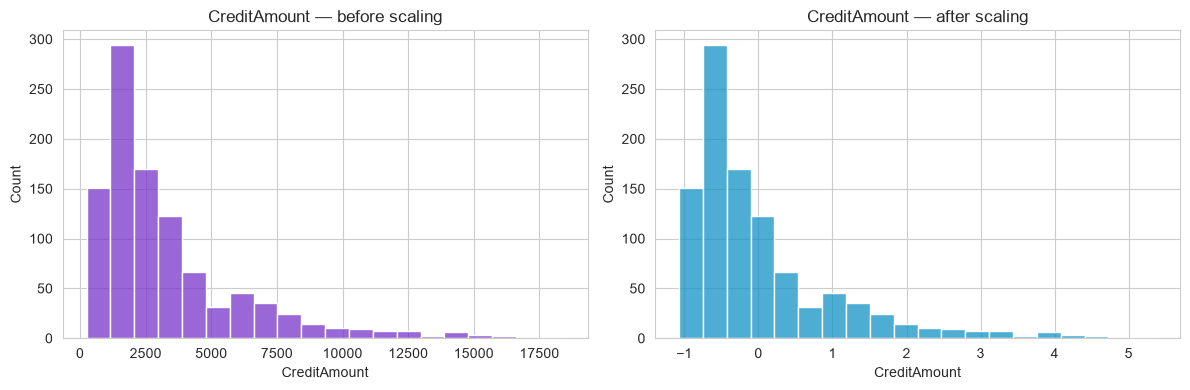

In [46]:
# note: This is a visual check: scaling changes the numbers on the axis, not the distribution pattern.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#7836C9")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#1192C5")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()


### 4.3 Feature selection

I rank potential predictors based on their relationship with **Risk**. This is an initial statistical check, not a prediction model.

In [47]:
# note: I separate X from Risk and rank features using an F-test. This is not model training.
# Feature scores are exploratory and should be checked again during proper model evaluation.

X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

selector = SelectKBest(score_func=f_classif, k="all")   # k="all" -> score every feature, keep none/drop none yet
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores


,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


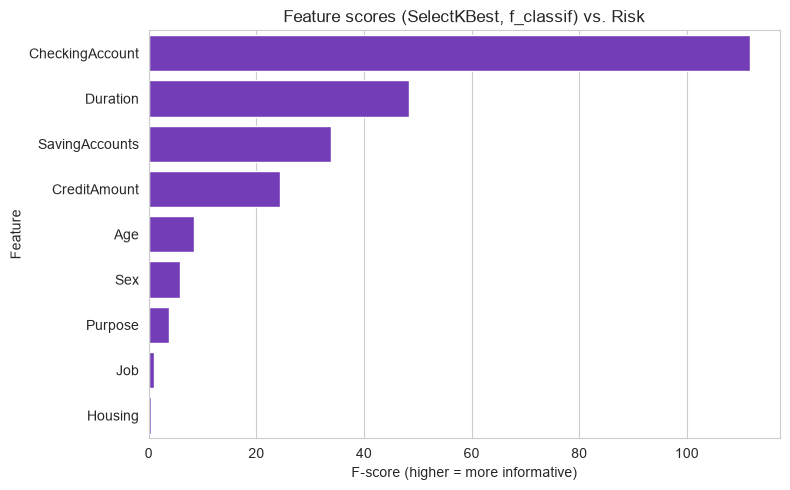

In [48]:
# note: The chart makes the feature ranking easier to read. A higher score is not proof of causation.

plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#7029CC")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()



## Summary

 **good analysis comes before modeling**.
 
 ---
**Each step answers a small question about the data. I should understand the reason behind the code, not just remember its syntax.**